# Midterm Project: Diabetes Prediction — Data Exploration and Preprocessing

**Course:** ITAI 1371 — Introduction to Machine Learning  
**Group:** Group 4  
**Dataset Source:** Kaggle

## Introduction

The purpose of this project is to explore, clean, and prepare a diabetes prediction dataset for future machine learning models. The dataset contains 100,000 patient records with health information such as age, BMI, blood glucose level, and diabetes status.

We will use Python to reduce the dataset to 50,000 records through stratified random sampling, preserving the original proportions of patients with and without diabetes. Next, we will split the data into 70% training and 30% testing.

We will perform Exploratory Data Analysis (EDA), data cleaning, encoding, scaling, and class balancing using SMOTENC on the training data only. The testing data will remain untouched.

Our goal is to prepare a clean dataset for building and evaluating diabetes prediction models in our final project.

## Step 1: Loading the Original Dataset

We will begin by loading the original dataset using Python and Pandas, displaying sample records, and checking the number of rows, columns, and diabetes cases.

In [2]:

# Step 1: Load and examine the original diabetes dataset

import pandas as pd

# Load the CSV file
df = pd.read_csv("diabetes_prediction_dataset[1].csv")

# Display the first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

# Display the dataset size
print("\nDataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display the number of patients in each class
print("\nDiabetes class distribution:")
print(df["diabetes"].value_counts().sort_index())

# Display the percentage of each class
print("\nDiabetes class percentages:")
print(df["diabetes"].value_counts(normalize=True).sort_index() * 100)


First 5 rows of the dataset:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0



Dataset shape: (100000, 9)

Column names:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

Diabetes class distribution:
diabetes
0    91500
1     8500
Name: count, dtype: int64

Diabetes class percentages:
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


## Step 2: Stratified Random Sampling

The original dataset contains 100,000 patient records. To follow our instructor's requirements, we will use stratified random sampling to reduce the dataset to 50,000 records while preserving the original diabetes class distribution.

We will randomly select 50% of patients without diabetes (`0`) and 50% of patients with diabetes (`1`). This ensures that both classes remain proportionally represented in the smaller dataset.

In [3]:

# Step 2: Stratified Random Sampling

# Randomly select 50% of records from each diabetes class
df_sampled = (
    df.groupby("diabetes", group_keys=False)
      .sample(frac=0.5, random_state=42)
      .sample(frac=1, random_state=42)
      .reset_index(drop=True)
)

# Display the new dataset size
print("Original dataset shape:", df.shape)
print("Sampled dataset shape:", df_sampled.shape)

# Display the new class distribution
print("\nSampled diabetes class distribution:")
print(df_sampled["diabetes"].value_counts().sort_index())

# Display the class percentages
print("\nSampled diabetes class percentages:")
print(df_sampled["diabetes"].value_counts(normalize=True).sort_index() * 100)

# Display the first 5 rows
print("\nFirst 5 rows of the sampled dataset:")
display(df_sampled.head())


Original dataset shape: (100000, 9)
Sampled dataset shape: (50000, 9)

Sampled diabetes class distribution:
diabetes
0    45750
1     4250
Name: count, dtype: int64

Sampled diabetes class percentages:
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64

First 5 rows of the sampled dataset:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Male,3.0,0,0,never,27.32,4.8,100,0
1,Male,47.0,0,0,current,27.81,6.1,160,0
2,Female,47.0,0,0,never,25.25,5.7,100,0
3,Female,23.0,0,0,never,27.98,6.0,80,0
4,Female,32.0,0,0,No Info,27.32,6.2,100,0


## Step 3: Splitting the Dataset into Training and Testing Sets

After reducing the dataset to 50,000 records, we will use Python to divide it into 70% training data and 30% testing data.

We will use stratified splitting to maintain the original diabetes class distribution in both datasets. Exploratory Data Analysis (EDA) and preprocessing will be performed only on the training data, while the testing data will remain untouched for future model evaluation.

In [4]:

# Step 3: Split the dataset into 70% training and 30% testing

from sklearn.model_selection import train_test_split

# Perform stratified train-test split
train_df, test_df = train_test_split(
    df_sampled,
    test_size=0.30,
    random_state=42,
    stratify=df_sampled["diabetes"]
)

# Display the number of records
print("Total sampled records:", len(df_sampled))
print("Training records:", len(train_df))
print("Testing records:", len(test_df))

# Check the training class distribution
print("\nTraining diabetes class distribution:")
print(train_df["diabetes"].value_counts().sort_index())

# Check the testing class distribution
print("\nTesting diabetes class distribution:")
print(test_df["diabetes"].value_counts().sort_index())

# Display percentages
print("\nTraining class percentages:")
print(train_df["diabetes"].value_counts(normalize=True).sort_index() * 100)

print("\nTesting class percentages:")
print(test_df["diabetes"].value_counts(normalize=True).sort_index() * 100)

# Save the split datasets
train_df.to_csv("diabetes_train_raw.csv", index=False)
test_df.to_csv("diabetes_test_untouched.csv", index=False)

print("\nTraining and testing datasets saved successfully!")


Total sampled records: 50000
Training records: 35000
Testing records: 15000

Training diabetes class distribution:
diabetes
0    32025
1     2975
Name: count, dtype: int64

Testing diabetes class distribution:
diabetes
0    13725
1     1275
Name: count, dtype: int64

Training class percentages:
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64

Testing class percentages:
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64

Training and testing datasets saved successfully!


## Step 4: Exploratory Data Analysis (EDA)

In this section, we will examine the training dataset to better understand its structure and identify potential data quality issues. We will check the data types, missing values, duplicate records, and summary statistics.

All exploratory analysis will be performed on the training data only. The testing dataset will remain untouched for future model evaluation.

In [5]:

# Step 4: Initial Exploratory Data Analysis (EDA)

# Display the first 5 rows of the training dataset
print("First 5 rows of training data:")
display(train_df.head())

# Check dataset information and data types
print("\nTraining dataset information:")
train_df.info()

# Check missing values
print("\nMissing values in each column:")
print(train_df.isnull().sum())

# Check duplicate records
print("\nNumber of duplicate records:")
print(train_df.duplicated().sum())

# Display summary statistics
print("\nSummary statistics:")
display(train_df.describe(include="all"))


First 5 rows of training data:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
28549,Male,59.0,0,0,No Info,24.36,6.6,159,0
9553,Male,66.0,0,0,never,30.49,5.7,140,0
12695,Female,16.0,0,0,No Info,29.33,4.5,200,0
489,Female,18.0,0,0,never,27.32,3.5,90,0
8169,Male,26.0,0,0,No Info,33.18,6.1,145,0



Training dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 35000 entries, 28549 to 20293
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender               35000 non-null  object 
 1   age                  35000 non-null  float64
 2   hypertension         35000 non-null  int64  
 3   heart_disease        35000 non-null  int64  
 4   smoking_history      35000 non-null  object 
 5   bmi                  35000 non-null  float64
 6   HbA1c_level          35000 non-null  float64
 7   blood_glucose_level  35000 non-null  int64  
 8   diabetes             35000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 2.7+ MB

Missing values in each column:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes          

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
count,35000,35000.000000,35000.000000,35000.000000,35000,35000.000000,35000.000000,35000.000000,35000.000000
unique,3,NaN,NaN,NaN,6,NaN,NaN,NaN,NaN
top,Female,NaN,NaN,NaN,No Info,NaN,NaN,NaN,NaN
freq,20499,NaN,NaN,NaN,12570,NaN,NaN,NaN,NaN
mean,NaN,41.921902,0.074000,0.039114,NaN,27.315983,5.531409,137.935286,0.085000
std,NaN,22.543585,0.261775,0.193870,NaN,6.633005,1.066081,40.491905,0.278886
min,NaN,0.080000,0.000000,0.000000,NaN,10.010000,3.500000,80.000000,0.000000
25%,NaN,24.000000,0.000000,0.000000,NaN,23.690000,4.800000,100.000000,0.000000
50%,NaN,43.000000,0.000000,0.000000,NaN,27.320000,5.800000,140.000000,0.000000
75%,NaN,60.000000,0.000000,0.000000,NaN,29.530000,6.200000,159.000000,0.000000


## Step 5: Data Visualization Before Preprocessing

In this section, we will use Matplotlib to visualize the training dataset before preprocessing. We will examine the distribution of diabetes cases, patient ages, BMI values, and smoking history.

These visualizations will help us understand the dataset, identify class imbalance, and compare the original training data with the processed data later.

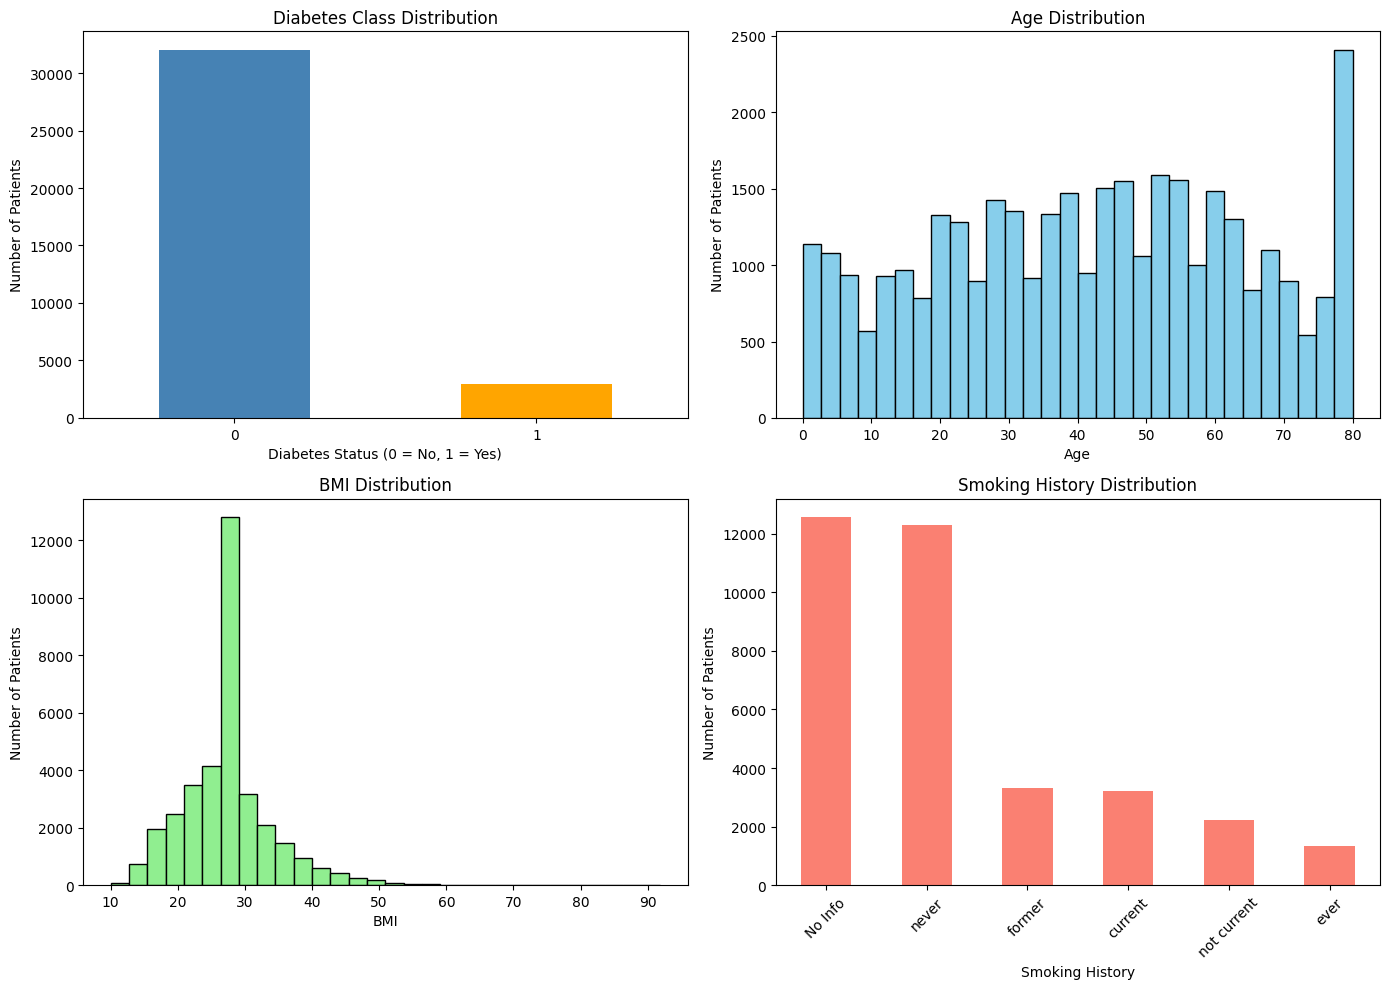

In [6]:

# Step 5: Visualize training data before preprocessing

import matplotlib.pyplot as plt

# Create four graphs
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Graph 1: Diabetes class distribution
train_df["diabetes"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0, 0], color=["steelblue", "orange"]
)
axes[0, 0].set_title("Diabetes Class Distribution")
axes[0, 0].set_xlabel("Diabetes Status (0 = No, 1 = Yes)")
axes[0, 0].set_ylabel("Number of Patients")
axes[0, 0].tick_params(axis="x", rotation=0)

# Graph 2: Age distribution
axes[0, 1].hist(train_df["age"], bins=30, color="skyblue",
                edgecolor="black")
axes[0, 1].set_title("Age Distribution")
axes[0, 1].set_xlabel("Age")
axes[0, 1].set_ylabel("Number of Patients")

# Graph 3: BMI distribution
axes[1, 0].hist(train_df["bmi"], bins=30, color="lightgreen",
                edgecolor="black")
axes[1, 0].set_title("BMI Distribution")
axes[1, 0].set_xlabel("BMI")
axes[1, 0].set_ylabel("Number of Patients")

# Graph 4: Smoking history distribution
train_df["smoking_history"].value_counts().plot(
    kind="bar", ax=axes[1, 1], color="salmon"
)
axes[1, 1].set_title("Smoking History Distribution")
axes[1, 1].set_xlabel("Smoking History")
axes[1, 1].set_ylabel("Number of Patients")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


### Interpretation of the Visualizations

The graphs show that the training dataset is imbalanced, with 91.5% of patients without diabetes and 8.5% with diabetes. The age distribution includes patients from different age groups, while BMI values are heavily concentrated around 27.32. Smoking history also contains a large number of `No Info` and `never` records.

These findings suggest that class balancing and categorical encoding will be important preprocessing steps. We will also investigate the unusual concentration of BMI values before making any changes.

## Step 6: Investigating Data Quality

Before preprocessing, we will examine unusual BMI values, smoking-history categories, and duplicate records. This analysis will help us identify potential data quality issues and determine which cleaning techniques are appropriate.

All investigations will be performed on the training dataset only.

In [7]:

# Step 6: Investigate data quality

# Check the most frequent BMI values
print("Top 10 most common BMI values:")
print(train_df["bmi"].value_counts().head(10))

# Check how many records have BMI = 27.32
bmi_count = (train_df["bmi"] == 27.32).sum()
print("\nRecords with BMI = 27.32:", bmi_count)
print("Percentage:", round(bmi_count / len(train_df) * 100, 2), "%")

# Examine smoking history categories
print("\nSmoking history categories:")
print(train_df["smoking_history"].value_counts())

# Examine gender categories
print("\nGender categories:")
print(train_df["gender"].value_counts())

# Check duplicate records
print("\nDuplicate records:", train_df.duplicated().sum())

# Display examples of duplicated rows
print("\nSample duplicate records:")
display(train_df[train_df.duplicated(keep=False)].head(10))


Top 10 most common BMI values:
bmi
27.32    8961
29.29      42
24.96      39
24.50      39
27.12      37
23.00      37
27.80      36
28.45      36
28.35      35
24.05      34
Name: count, dtype: int64

Records with BMI = 27.32: 8961
Percentage: 25.6 %

Smoking history categories:
smoking_history
No Info        12570
never          12313
former          3334
current         3212
not current     2228
ever            1343
Name: count, dtype: int64

Gender categories:
gender
Female    20499
Male      14492
Other         9
Name: count, dtype: int64

Duplicate records: 550

Sample duplicate records:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
11044,Female,41.0,0,0,No Info,27.32,6.2,160,0
1781,Female,40.0,0,0,No Info,27.32,4.8,126,0
38347,Male,18.0,0,0,No Info,27.32,3.5,160,0
6248,Female,55.0,0,0,former,27.32,6.5,80,0
4826,Male,43.0,0,0,No Info,27.32,6.0,160,0
32148,Male,20.0,0,0,No Info,27.32,5.0,126,0
28909,Male,47.0,0,0,No Info,27.32,4.5,80,0
24461,Female,11.0,0,0,No Info,19.42,4.0,80,0
38162,Male,54.0,0,0,No Info,27.32,6.5,140,0
46526,Female,36.0,0,0,No Info,27.32,4.0,159,0


### Step 6: Data Quality Findings

Our analysis identified 8,961 records (25.6%) with a BMI of 27.32, suggesting a possible concentration caused by earlier data processing. We also found 12,570 records with `No Info` for smoking history and 550 duplicate rows.

These findings highlight potential data quality issues. We will preserve the original BMI values, treat `No Info` as an unknown smoking-history category, and investigate duplicates before making changes. All preprocessing will be performed using Python on the training data only.

## Step 7: Preparing the Training Data

In this section, we will create a working copy of the training dataset and begin cleaning categorical values. We will replace `No Info` in smoking history with `Unknown` to make the meaning clearer while preserving the original records.

The original training and testing datasets will remain unchanged.

In [8]:

# Step 7: Create a working copy and clean smoking history

# Create a copy of the training dataset
train_clean = train_df.copy()

# Rename the "No Info" smoking category to "Unknown"
train_clean["smoking_history"] = (
    train_clean["smoking_history"].replace("No Info", "Unknown")
)

# Compare smoking history before and after cleaning
print("Before cleaning:")
print(train_df["smoking_history"].value_counts())

print("\nAfter cleaning:")
print(train_clean["smoking_history"].value_counts())

# Check that the number of records has not changed
print("\nOriginal training records:", len(train_df))
print("Cleaned training records:", len(train_clean))

# Display sample cleaned records
print("\nFirst 5 cleaned records:")
display(train_clean.head())


Before cleaning:
smoking_history
No Info        12570
never          12313
former          3334
current         3212
not current     2228
ever            1343
Name: count, dtype: int64

After cleaning:
smoking_history
Unknown        12570
never          12313
former          3334
current         3212
not current     2228
ever            1343
Name: count, dtype: int64

Original training records: 35000
Cleaned training records: 35000

First 5 cleaned records:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
28549,Male,59.0,0,0,Unknown,24.36,6.6,159,0
9553,Male,66.0,0,0,never,30.49,5.7,140,0
12695,Female,16.0,0,0,Unknown,29.33,4.5,200,0
489,Female,18.0,0,0,never,27.32,3.5,90,0
8169,Male,26.0,0,0,Unknown,33.18,6.1,145,0


## Step 8: Encoding Categorical Features

In this section, we will convert the categorical features `gender` and `smoking_history` into numerical representations using OrdinalEncoder.

This will prepare the training data for SMOTENC class balancing. The encoded numbers represent categories rather than numerical rankings. The original training and testing datasets will remain unchanged.

In [9]:

# Step 8: Encode categorical features for SMOTENC

from sklearn.preprocessing import OrdinalEncoder

# Create a new working copy
train_encoded = train_clean.copy()

# Identify categorical columns
categorical_columns = [
    "gender",
    "smoking_history",
    "hypertension",
    "heart_disease"
]

# Encode text-based categorical columns
text_columns = ["gender", "smoking_history"]

encoder = OrdinalEncoder()

train_encoded[text_columns] = encoder.fit_transform(
    train_encoded[text_columns]
)

# Display category mappings
for column, categories in zip(text_columns, encoder.categories_):
    print(f"\n{column} encoding:")
    for number, category in enumerate(categories):
        print(f"{category} = {number}")

# Compare original and encoded data
print("\nBefore encoding:")
display(train_clean.head())

print("\nAfter encoding:")
display(train_encoded.head())

# Verify dataset size
print("\nEncoded dataset shape:", train_encoded.shape)



gender encoding:
Female = 0
Male = 1
Other = 2

smoking_history encoding:
Unknown = 0
current = 1
ever = 2
former = 3
never = 4
not current = 5

Before encoding:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
28549,Male,59.0,0,0,Unknown,24.36,6.6,159,0
9553,Male,66.0,0,0,never,30.49,5.7,140,0
12695,Female,16.0,0,0,Unknown,29.33,4.5,200,0
489,Female,18.0,0,0,never,27.32,3.5,90,0
8169,Male,26.0,0,0,Unknown,33.18,6.1,145,0



After encoding:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
28549,1.0,59.0,0,0,0.0,24.36,6.6,159,0
9553,1.0,66.0,0,0,4.0,30.49,5.7,140,0
12695,0.0,16.0,0,0,0.0,29.33,4.5,200,0
489,0.0,18.0,0,0,4.0,27.32,3.5,90,0
8169,1.0,26.0,0,0,0.0,33.18,6.1,145,0



Encoded dataset shape: (35000, 9)


## Step 9: Feature Scaling

In this section, we will use StandardScaler to standardize the numerical features: age, BMI, HbA1c level, and blood glucose level.

Standardization transforms numerical features to have a mean close to 0 and a standard deviation close to 1. This helps prevent features with larger numerical ranges from dominating distance-based preprocessing techniques such as SMOTENC.

Categorical features and the diabetes target variable will not be scaled. All scaling parameters will be calculated using the training data only.

In [10]:

# Step 9: Standardize numerical features

from sklearn.preprocessing import StandardScaler

# Create a new working copy
train_scaled = train_encoded.copy()

# Select numerical features
numerical_columns = [
    "age",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level"
]

# Create and fit the scaler on training data only
scaler = StandardScaler()

train_scaled[numerical_columns] = scaler.fit_transform(
    train_scaled[numerical_columns]
)

# Compare values before and after scaling
print("Before scaling:")
display(train_encoded[numerical_columns].head())

print("\nAfter scaling:")
display(train_scaled[numerical_columns].head())

# Check the mean and standard deviation
print("\nMean after scaling:")
print(train_scaled[numerical_columns].mean().round(4))

print("\nStandard deviation after scaling:")
print(train_scaled[numerical_columns].std().round(4))

# Verify dataset shape
print("\nScaled dataset shape:", train_scaled.shape)


Before scaling:


,age,bmi,HbA1c_level,blood_glucose_level
28549,59.0,24.36,6.6,159
9553,66.0,30.49,5.7,140
12695,16.0,29.33,4.5,200
489,18.0,27.32,3.5,90
8169,26.0,33.18,6.1,145



After scaling:


,age,bmi,HbA1c_level,blood_glucose_level
28549,0.757570,-0.445654,1.002369,0.520228
9553,1.068084,0.478526,0.158143,0.050992
12695,-1.149874,0.303640,-0.967490,1.532790
489,-1.061155,0.000606,-1.905518,-1.183841
8169,-0.706282,0.884079,0.533355,0.174475



Mean after scaling:
age                   -0.0
bmi                    0.0
HbA1c_level            0.0
blood_glucose_level   -0.0
dtype: float64

Standard deviation after scaling:
age                    1.0
bmi                    1.0
HbA1c_level            1.0
blood_glucose_level    1.0
dtype: float64

Scaled dataset shape: (35000, 9)


## Step 10: Class Balancing Using SMOTENC

The training dataset is imbalanced, with 91.5% of records belonging to patients without diabetes and 8.5% belonging to patients with diabetes.

To address this imbalance, we will apply Synthetic Minority Over-sampling Technique for Nominal and Continuous features (SMOTENC). This technique creates synthetic examples of the minority class while handling both numerical and categorical features.

SMOTENC will be applied only to the training dataset. The testing dataset will remain untouched to preserve the original class distribution for future model evaluation.

Before SMOTENC:
diabetes
0    32025
1     2975
Name: count, dtype: int64

After SMOTENC:
diabetes
0    32025
1    32025
Name: count, dtype: int64

Original training shape: (35000, 9)
Balanced training shape: (64050, 9)


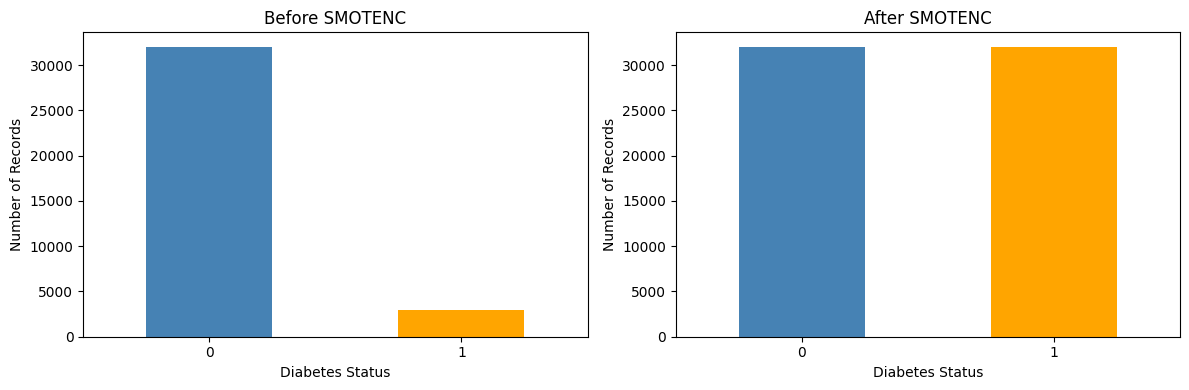


First 5 balanced records:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,1.0,0.757570,0,0,0.0,-0.445654,1.002369,0.520228,0
1,1.0,1.068084,0,0,4.0,0.478526,0.158143,0.050992,0
2,0.0,-1.149874,0,0,0.0,0.303640,-0.967490,1.532790,0
3,0.0,-1.061155,0,0,4.0,0.000606,-1.905518,-1.183841,0
4,1.0,-0.706282,0,0,0.0,0.884079,0.533355,0.174475,0


In [11]:

# Step 10: Balance the training data using SMOTENC

# Install imbalanced-learn if necessary
%pip install -q imbalanced-learn

import pandas as pd
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTENC

# Separate input features and target
X_train = train_scaled.drop(columns=["diabetes"])
y_train = train_scaled["diabetes"]

# Identify categorical columns
categorical_columns = [
    "gender",
    "smoking_history",
    "hypertension",
    "heart_disease"
]

# Create the SMOTENC sampler
smote_nc = SMOTENC(
    categorical_features=categorical_columns,
    random_state=42,
    k_neighbors=5
)

# Apply SMOTENC only to training data
X_balanced, y_balanced = smote_nc.fit_resample(
    X_train, y_train
)

# Combine features and target into one DataFrame
train_balanced = X_balanced.copy()
train_balanced["diabetes"] = y_balanced

# Display class distribution before balancing
print("Before SMOTENC:")
print(y_train.value_counts().sort_index())

# Display class distribution after balancing
print("\nAfter SMOTENC:")
print(y_balanced.value_counts().sort_index())

# Display dataset sizes
print("\nOriginal training shape:", train_scaled.shape)
print("Balanced training shape:", train_balanced.shape)

# Plot before and after class distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

y_train.value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0],
    color=["steelblue", "orange"]
)
axes[0].set_title("Before SMOTENC")
axes[0].set_xlabel("Diabetes Status")
axes[0].set_ylabel("Number of Records")
axes[0].tick_params(axis="x", rotation=0)

y_balanced.value_counts().sort_index().plot(
    kind="bar",
    ax=axes[1],
    color=["steelblue", "orange"]
)
axes[1].set_title("After SMOTENC")
axes[1].set_xlabel("Diabetes Status")
axes[1].set_ylabel("Number of Records")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

# Display the first 5 balanced records
print("\nFirst 5 balanced records:")
display(train_balanced.head())


### Step 10: SMOTENC Results and Interpretation

Before class balancing, the training dataset contained 32,025 records without diabetes (91.5%) and 2,975 records with diabetes (8.5%). This showed a significant class imbalance.

After applying SMOTENC, both classes contained 32,025 records, resulting in a balanced training dataset of 64,050 records. SMOTENC generated 29,050 synthetic examples of the minority class.

The before-and-after graphs demonstrate that class balancing was successful. This technique may help future machine learning models recognize diabetes-positive cases more effectively. The testing dataset remained untouched.

## Step 11: Validating the Balanced Dataset

In this section, we will verify the quality of the balanced training dataset by checking its size, missing values, duplicate records, and categorical feature values.

This validation will help confirm that the processed dataset is ready for future machine learning applications.

In [12]:

# Step 11: Validate the balanced training dataset

# Check dataset size
print("Balanced dataset shape:", train_balanced.shape)

# Check missing values
print("\nMissing values:")
print(train_balanced.isnull().sum())

# Check duplicate records
print("\nDuplicate records:")
print(train_balanced.duplicated().sum())

# Check diabetes class distribution
print("\nDiabetes class distribution:")
print(train_balanced["diabetes"].value_counts().sort_index())

# Check categorical values
categorical_columns = [
    "gender",
    "smoking_history",
    "hypertension",
    "heart_disease"
]

for column in categorical_columns:
    print(f"\nUnique values in {column}:")
    print(sorted(train_balanced[column].unique()))

# Display a sample of synthetic diabetes-positive records
print("\nSample synthetic diabetes-positive records:")
display(
    train_balanced[
        train_balanced["diabetes"] == 1
    ].tail(5)
)


Balanced dataset shape: (64050, 9)

Missing values:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Duplicate records:
562

Diabetes class distribution:
diabetes
0    32025
1    32025
Name: count, dtype: int64

Unique values in gender:
[np.float64(0.0), np.float64(1.0), np.float64(2.0)]

Unique values in smoking_history:
[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]

Unique values in hypertension:
[np.int64(0), np.int64(1)]

Unique values in heart_disease:
[np.int64(0), np.int64(1)]

Sample synthetic diabetes-positive records:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
64045,0.0,1.676316,0,0,3.0,-0.522868,1.269348,4.002455,1
64046,1.0,0.848447,0,0,5.0,0.000606,1.187069,2.522842,1
64047,0.0,1.207991,0,0,4.0,0.171572,3.094914,4.002455,1
64048,0.0,0.846809,0,0,3.0,0.478136,0.531152,0.419991,1
64049,0.0,1.671261,0,0,4.0,0.208722,0.420112,0.544924,1


## Step 12: Feature Engineering

Feature engineering involves creating new features from existing data to provide additional information for machine learning.

In this section, we will create a `high_bmi` feature to indicate whether a patient's BMI is 30 or higher. This feature may help future models identify patterns associated with diabetes.

We will create this feature using the original BMI values and treat it as a categorical feature during class balancing.

In [13]:

# Step 12: Create a new feature using original BMI values

# Start with the encoded training dataset
train_features = train_encoded.copy()

# Create a high BMI indicator
train_features["high_bmi"] = (
    train_features["bmi"] >= 30
).astype(int)

# Display counts for the new feature
print("High BMI distribution:")
print(train_features["high_bmi"].value_counts().sort_index())

# Compare original BMI and new feature
print("\nBMI and high_bmi comparison:")
display(train_features[["bmi", "high_bmi"]].head(10))

# Verify dataset shape
print("\nDataset shape after feature engineering:")
print(train_features.shape)


High BMI distribution:
high_bmi
0    26827
1     8173
Name: count, dtype: int64

BMI and high_bmi comparison:


,bmi,high_bmi
28549,24.36,0
9553,30.49,1
12695,29.33,0
489,27.32,0
8169,33.18,1
41068,14.98,0
38290,21.67,0
26282,27.32,0
41108,27.32,0
20136,38.53,1



Dataset shape after feature engineering:
(35000, 10)


## Step 13: Final Preprocessing and Class Balancing

After creating the `high_bmi` feature, we will standardize the numerical features and apply SMOTENC again using the updated training dataset.

The new `high_bmi` feature will be treated as categorical, along with gender, smoking history, hypertension, and heart disease. This ensures that synthetic records contain valid categorical values.

The testing dataset will remain untouched.

Before SMOTENC:
diabetes
0    32025
1     2975
Name: count, dtype: int64

After SMOTENC:
diabetes
0    32025
1    32025
Name: count, dtype: int64

Final balanced dataset shape:
(64050, 10)

Missing values:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
high_bmi               0
diabetes               0
dtype: int64

High BMI unique values:
[0 1]

First 5 records:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,high_bmi,diabetes
0,1.0,0.757570,0,0,0.0,-0.445654,1.002369,0.520228,0,0
1,1.0,1.068084,0,0,4.0,0.478526,0.158143,0.050992,1,0
2,0.0,-1.149874,0,0,0.0,0.303640,-0.967490,1.532790,0,0
3,0.0,-1.061155,0,0,4.0,0.000606,-1.905518,-1.183841,0,0
4,1.0,-0.706282,0,0,0.0,0.884079,0.533355,0.174475,1,0


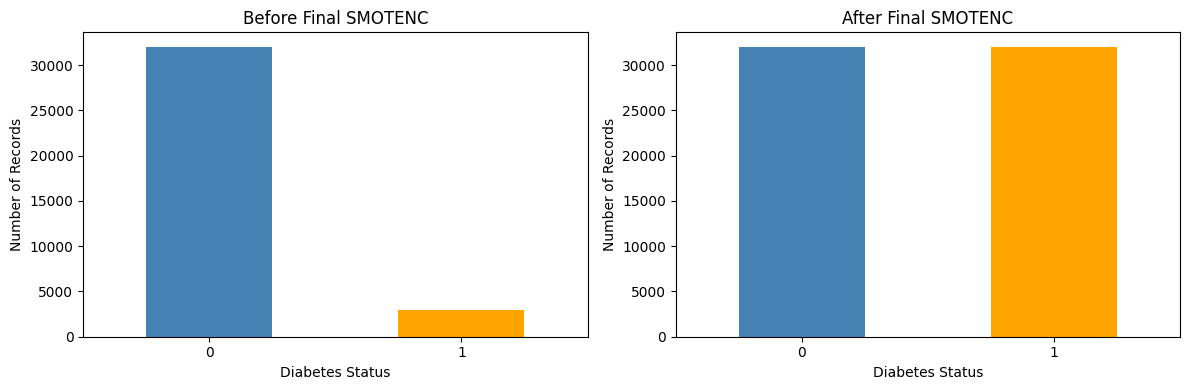

In [14]:

# Step 13: Final scaling and SMOTENC with feature engineering

from imblearn.over_sampling import SMOTENC
import matplotlib.pyplot as plt

# Create a copy of the training data with the new feature
train_final_scaled = train_features.copy()

# Apply the scaler fitted on training data in Step 9
train_final_scaled[numerical_columns] = scaler.transform(
    train_final_scaled[numerical_columns]
)

# Separate features and target
X_final = train_final_scaled.drop(columns=["diabetes"])
y_final = train_final_scaled["diabetes"]

# Include the new categorical feature
final_categorical_columns = [
    "gender",
    "smoking_history",
    "hypertension",
    "heart_disease",
    "high_bmi"
]

# Apply SMOTENC
smote_final = SMOTENC(
    categorical_features=final_categorical_columns,
    random_state=42,
    k_neighbors=5
)

X_final_balanced, y_final_balanced = smote_final.fit_resample(
    X_final, y_final
)

# Combine features and target
train_final_balanced = X_final_balanced.copy()
train_final_balanced["diabetes"] = y_final_balanced

# Display class counts
print("Before SMOTENC:")
print(y_final.value_counts().sort_index())

print("\nAfter SMOTENC:")
print(y_final_balanced.value_counts().sort_index())

# Display final dataset shape
print("\nFinal balanced dataset shape:")
print(train_final_balanced.shape)

# Check missing values
print("\nMissing values:")
print(train_final_balanced.isnull().sum())

# Check the new feature
print("\nHigh BMI unique values:")
print(train_final_balanced["high_bmi"].unique())

# Display sample records
print("\nFirst 5 records:")
display(train_final_balanced.head())

# Compare class distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

y_final.value_counts().sort_index().plot(
    kind="bar", ax=axes[0],
    color=["steelblue", "orange"]
)
axes[0].set_title("Before Final SMOTENC")
axes[0].set_xlabel("Diabetes Status")
axes[0].set_ylabel("Number of Records")
axes[0].tick_params(axis="x", rotation=0)

y_final_balanced.value_counts().sort_index().plot(
    kind="bar", ax=axes[1],
    color=["steelblue", "orange"]
)
axes[1].set_title("After Final SMOTENC")
axes[1].set_xlabel("Diabetes Status")
axes[1].set_ylabel("Number of Records")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


## Step 14: Validating the Engineered BMI Feature

After applying SMOTENC, we will verify that the `high_bmi` feature remains consistent with the BMI values in the balanced training dataset.

Since BMI was standardized before class balancing, we will convert it back to its original scale for this comparison. Any inconsistent `high_bmi` values will be corrected using Python.

This ensures that our engineered feature accurately represents the BMI values in the final processed dataset.

In [15]:

# Step 14: Validate and correct the high_bmi feature

import numpy as np

# Create a copy of the balanced training dataset
train_final_checked = train_final_balanced.copy()

# Recover BMI in its original units
bmi_position = numerical_columns.index("bmi")

bmi_original = (
    train_final_checked["bmi"] * scaler.scale_[bmi_position]
    + scaler.mean_[bmi_position]
)

# Calculate the correct high_bmi values
correct_high_bmi = (bmi_original >= 30).astype(int)

# Count inconsistencies before correction
mismatches = (
    train_final_checked["high_bmi"] != correct_high_bmi
).sum()

print("Inconsistent high_bmi records before correction:", mismatches)

# Correct the engineered feature
train_final_checked["high_bmi"] = correct_high_bmi

# Verify the correction
remaining = (
    train_final_checked["high_bmi"] !=
    (bmi_original >= 30).astype(int)
).sum()

print("Inconsistent records after correction:", remaining)

# Check dataset shape
print("\nFinal dataset shape:", train_final_checked.shape)

# Check diabetes class distribution
print("\nFinal diabetes class distribution:")
print(train_final_checked["diabetes"].value_counts().sort_index())

# Display sample records
print("\nFirst 5 corrected records:")
display(train_final_checked.head())


Inconsistent high_bmi records before correction: 65
Inconsistent records after correction: 0

Final dataset shape: (64050, 10)

Final diabetes class distribution:
diabetes
0    32025
1    32025
Name: count, dtype: int64

First 5 corrected records:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,high_bmi,diabetes
0,1.0,0.757570,0,0,0.0,-0.445654,1.002369,0.520228,0,0
1,1.0,1.068084,0,0,4.0,0.478526,0.158143,0.050992,1,0
2,0.0,-1.149874,0,0,0.0,0.303640,-0.967490,1.532790,0,0
3,0.0,-1.061155,0,0,4.0,0.000606,-1.905518,-1.183841,0,0
4,1.0,-0.706282,0,0,0.0,0.884079,0.533355,0.174475,1,0


## Step 15: Final Data Quality Validation

In this section, we will perform a final quality check on the processed training dataset. We will examine missing values, duplicate records, categorical values, and class distribution.

This validation will help confirm that the dataset is ready to be saved and used for future machine learning models.

In [16]:

# Step 15: Final Data Quality Validation

# Check dataset shape
print("Final dataset shape:")
print(train_final_checked.shape)

# Check missing values
print("\nMissing values:")
print(train_final_checked.isnull().sum())

# Check duplicate records
print("\nDuplicate records:")
print(train_final_checked.duplicated().sum())

# Check diabetes class distribution
print("\nDiabetes class distribution:")
print(train_final_checked["diabetes"].value_counts().sort_index())

# Check categorical features
categorical_columns = [
    "gender",
    "smoking_history",
    "hypertension",
    "heart_disease",
    "high_bmi"
]

for column in categorical_columns:
    print(f"\nUnique values in {column}:")
    print(sorted(train_final_checked[column].unique()))

# Check summary statistics
print("\nFinal summary statistics:")
display(train_final_checked.describe())

# Display sample records
print("\nSample of final processed data:")
display(train_final_checked.head())


Final dataset shape:
(64050, 10)

Missing values:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
high_bmi               0
diabetes               0
dtype: int64

Duplicate records:
565

Diabetes class distribution:
diabetes
0    32025
1    32025
Name: count, dtype: int64

Unique values in gender:
[np.float64(0.0), np.float64(1.0), np.float64(2.0)]

Unique values in smoking_history:
[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]

Unique values in hypertension:
[np.int64(0), np.int64(1)]

Unique values in heart_disease:
[np.int64(0), np.int64(1)]

Unique values in high_bmi:
[np.int64(0), np.int64(1)]

Final summary statistics:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,high_bmi,diabetes
count,64050.000000,64050.000000,64050.000000,64050.000000,64050.000000,64050.000000,64050.000000,64050.000000,64050.000000,64050.000000
mean,0.440016,0.391948,0.147432,0.075628,2.463544,0.323512,0.588241,0.618314,0.356112,0.500000
std,0.496676,0.945069,0.354539,0.264405,1.804620,1.097897,1.185798,1.388901,0.478853,0.500004
min,0.000000,-1.856071,0.000000,0.000000,0.000000,-2.609109,-1.905518,-1.430807,0.000000,0.000000
25%,0.000000,-0.218331,0.000000,0.000000,0.000000,-0.199910,0.158143,-0.195975,0.000000,0.000000
50%,0.000000,0.580133,0.000000,0.000000,3.000000,0.000606,0.533355,0.421441,0.000000,0.500000
75%,1.000000,1.129762,0.000000,0.000000,4.000000,0.853905,1.002369,1.532790,1.000000,1.000000
max,2.000000,1.689112,1.000000,1.000000,5.000000,9.724844,3.253636,4.002455,1.000000,1.000000



Sample of final processed data:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,high_bmi,diabetes
0,1.0,0.757570,0,0,0.0,-0.445654,1.002369,0.520228,0,0
1,1.0,1.068084,0,0,4.0,0.478526,0.158143,0.050992,1,0
2,0.0,-1.149874,0,0,0.0,0.303640,-0.967490,1.532790,0,0
3,0.0,-1.061155,0,0,4.0,0.000606,-1.905518,-1.183841,0,0
4,1.0,-0.706282,0,0,0.0,0.884079,0.533355,0.174475,1,0


## Step 16: Before-and-After Preprocessing Comparison

In this section, we will compare the original training data with the final processed training data using Matplotlib.

We will examine changes in age, BMI, and diabetes class distribution. This comparison demonstrates the effects of feature scaling and SMOTENC class balancing.

All comparisons use training data only. The testing dataset remains untouched.

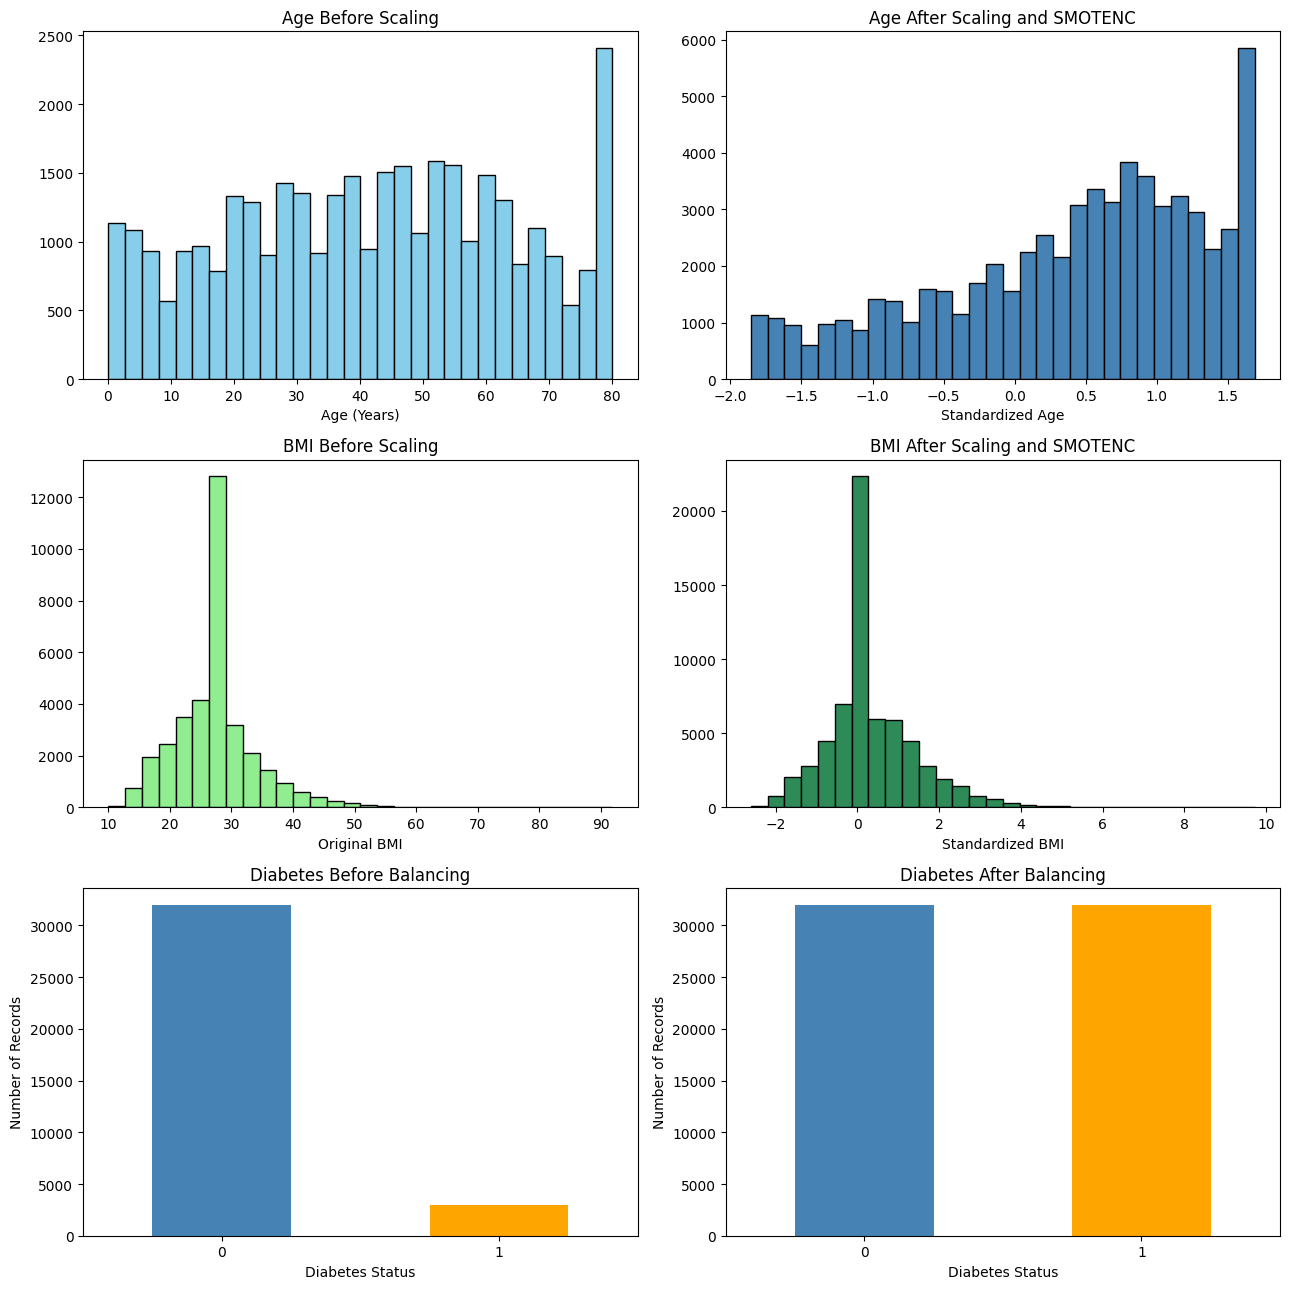

In [17]:

# Step 16: Compare training data before and after preprocessing

import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(13, 13))

# Age before preprocessing
axes[0, 0].hist(train_df["age"], bins=30,
                color="skyblue", edgecolor="black")
axes[0, 0].set_title("Age Before Scaling")
axes[0, 0].set_xlabel("Age (Years)")

# Age after preprocessing
axes[0, 1].hist(train_final_checked["age"], bins=30,
                color="steelblue", edgecolor="black")
axes[0, 1].set_title("Age After Scaling and SMOTENC")
axes[0, 1].set_xlabel("Standardized Age")

# BMI before preprocessing
axes[1, 0].hist(train_df["bmi"], bins=30,
                color="lightgreen", edgecolor="black")
axes[1, 0].set_title("BMI Before Scaling")
axes[1, 0].set_xlabel("Original BMI")

# BMI after preprocessing
axes[1, 1].hist(train_final_checked["bmi"], bins=30,
                color="seagreen", edgecolor="black")
axes[1, 1].set_title("BMI After Scaling and SMOTENC")
axes[1, 1].set_xlabel("Standardized BMI")

# Diabetes before balancing
train_df["diabetes"].value_counts().sort_index().plot(
    kind="bar", ax=axes[2, 0],
    color=["steelblue", "orange"]
)
axes[2, 0].set_title("Diabetes Before Balancing")
axes[2, 0].set_xlabel("Diabetes Status")
axes[2, 0].set_ylabel("Number of Records")
axes[2, 0].tick_params(axis="x", rotation=0)

# Diabetes after balancing
train_final_checked["diabetes"].value_counts().sort_index().plot(
    kind="bar", ax=axes[2, 1],
    color=["steelblue", "orange"]
)
axes[2, 1].set_title("Diabetes After Balancing")
axes[2, 1].set_xlabel("Diabetes Status")
axes[2, 1].set_ylabel("Number of Records")
axes[2, 1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


## Step 17: Final Dataset Verification

In this section, we will perform the final checks before exporting our datasets. We will verify the number of records, missing values, class distribution, and consistency of the engineered features.

We will also confirm that the original testing dataset still contains 15,000 records and has not been modified or balanced.

In [19]:

# Step 17: Final verification before exporting

# Check dataset sizes
print("Original sampled dataset:", df_sampled.shape)
print("Original training dataset:", train_df.shape)
print("Final processed training dataset:", train_final_checked.shape)
print("Untouched testing dataset:", test_df.shape)

# Check missing values
print("\nMissing values in processed training data:")
print(train_final_checked.isnull().sum())

# Check duplicate records
print("\nDuplicate records in processed training data:")
print(train_final_checked.duplicated().sum())

# Verify training class distribution
print("\nProcessed training class distribution:")
print(train_final_checked["diabetes"].value_counts().sort_index())

# Verify testing class distribution
print("\nTesting class distribution:")
print(test_df["diabetes"].value_counts().sort_index())

# Verify high_bmi consistency
bmi_index = numerical_columns.index("bmi")

original_bmi = (
    train_final_checked["bmi"] * scaler.scale_[bmi_index]
    + scaler.mean_[bmi_index]
)

inconsistent_bmi = (
    train_final_checked["high_bmi"] !=
    (original_bmi >= 30).astype(int)
).sum()

print("\nInconsistent high_bmi values:", inconsistent_bmi)

# Final verification
assert len(df_sampled) == 50000
assert len(train_df) == 35000
assert len(test_df) == 15000
assert len(train_final_checked) == 64050
assert train_final_checked.isnull().sum().sum() == 0
assert inconsistent_bmi == 0

print("\nFinal verification checks passed!")


Original sampled dataset: (50000, 9)
Original training dataset: (35000, 9)
Final processed training dataset: (64050, 10)
Untouched testing dataset: (15000, 9)

Missing values in processed training data:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
high_bmi               0
diabetes               0
dtype: int64

Duplicate records in processed training data:
565

Processed training class distribution:
diabetes
0    32025
1    32025
Name: count, dtype: int64

Testing class distribution:
diabetes
0    13725
1     1275
Name: count, dtype: int64

Inconsistent high_bmi values: 0

Final verification checks passed!


## Step 18: Exporting the Final Datasets

In this section, we will export the final processed training dataset, the original training dataset, and the untouched testing dataset as CSV files.

The processed training dataset contains 64,050 records after feature engineering, scaling, and SMOTENC class balancing. The testing dataset contains 15,000 original records and has not been used for preprocessing or balancing.

All datasets will be saved using Python without manually modifying the original Kaggle dataset.

In [20]:

# Step 18: Export final datasets

# Save the final processed and balanced training data
train_final_checked.to_csv(
    "Group4_Diabetes_Processed_Training.csv",
    index=False
)

# Save the original training data
train_df.to_csv(
    "Group4_Diabetes_Original_Training.csv",
    index=False
)

# Save the untouched testing data
test_df.to_csv(
    "Group4_Diabetes_Untouched_Testing.csv",
    index=False
)

# Verify that files were saved
import os

files = [
    "Group4_Diabetes_Processed_Training.csv",
    "Group4_Diabetes_Original_Training.csv",
    "Group4_Diabetes_Untouched_Testing.csv"
]

for filename in files:
    print(
        filename,
        "- Saved successfully:",
        os.path.exists(filename)
    )


Group4_Diabetes_Processed_Training.csv - Saved successfully: True
Group4_Diabetes_Original_Training.csv - Saved successfully: True
Group4_Diabetes_Untouched_Testing.csv - Saved successfully: True


## Step 19: Downloading the Final Datasets

After completing preprocessing and validating the results, we will download the three CSV files generated by Python. These files will be included in our GitHub repository as evidence of the original training data, the final processed training data, and the untouched testing data.

In [21]:

# Step 19: Download the final CSV files

from google.colab import files

files.download("Group4_Diabetes_Processed_Training.csv")
files.download("Group4_Diabetes_Original_Training.csv")
files.download("Group4_Diabetes_Untouched_Testing.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>